1. Install libraries

In [15]:
!pip install xgboost imbalanced-learn

2. Import libraries

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

2.Load the Data Set

In [17]:
transaction = pd.read_csv("/train_transaction.csv")
identity = pd.read_csv("/train_identity.csv")

print(transaction.shape)
print(identity.shape)

(38889, 394)
(144233, 41)


Merge them using TransactionID:

In [18]:
df = transaction.merge(identity, on="TransactionID", how="left")

print(df.shape)

(38889, 434)


4. Check the fraud distribution

In [19]:
print(df["isFraud"].value_counts())

print(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    37784
1     1105
Name: count, dtype: int64
isFraud
0    97.15858
1     2.84142
Name: proportion, dtype: float64


Visualize it:

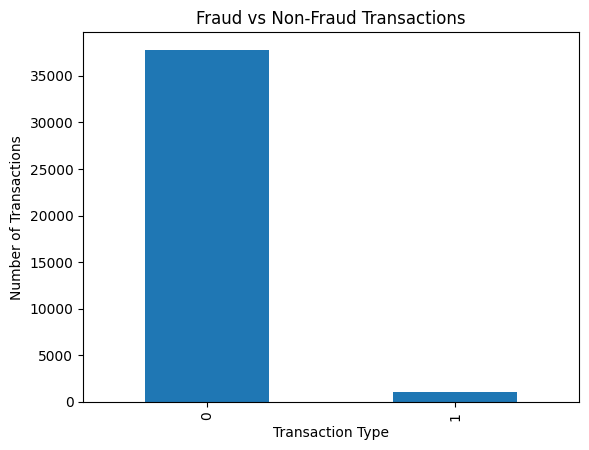

In [20]:
df["isFraud"].value_counts().plot(kind="bar")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

5. Prepare the data

In [21]:
X = df.drop("isFraud", axis=1)
y = df["isFraud"]

Remove TransactionID because it is an identifier rather than a useful predictive feature:

In [22]:
X = X.drop("TransactionID", axis=1)

Handle categorical columns.

In [23]:
categorical_columns = X.select_dtypes(include=["object"]).columns

X[categorical_columns] = X[categorical_columns].fillna("Missing")

X = pd.get_dummies(X, columns=categorical_columns)

Handle numerical missing values:

In [24]:
X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median(numeric_only=True))

6. Split the dataset

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (31111, 1321)
Testing data: (7778, 1321)


7. Apply SMOTE

In [26]:
smote = SMOTE(
    sampling_strategy=0.3,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [27]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
isFraud
0    30227
1      884
Name: count, dtype: int64

After SMOTE:
isFraud
0    30227
1     9068
Name: count, dtype: int64


8. Train XGBoost

In [28]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

In [29]:
model.fit(
    X_train_smote,
    y_train_smote
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

9. Get fraud probabilities

In [30]:
y_prob = model.predict_proba(X_test)[:, 1]

print(y_prob[:10])

[0.00464607 0.00211016 0.00102108 0.00218435 0.00089812 0.01840524
 0.0005637  0.00082578 0.00201271 0.00049137]


10. Tune the decision threshold

In [31]:
thresholds = np.arange(0.1, 0.91, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

Create a table:

In [32]:
results_df = pd.DataFrame(
    results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

print(results_df)

    Threshold  Precision    Recall        F1
0        0.10   0.612903  0.687783  0.648188
1        0.15   0.750000  0.665158  0.705036
2        0.20   0.790960  0.633484  0.703518
3        0.25   0.829114  0.592760  0.691293
4        0.30   0.857143  0.570136  0.684783
5        0.35   0.874074  0.533937  0.662921
6        0.40   0.904000  0.511312  0.653179
7        0.45   0.915966  0.493213  0.641176
8        0.50   0.921739  0.479638  0.630952
9        0.55   0.936364  0.466063  0.622356
10       0.60   0.952381  0.452489  0.613497
11       0.65   0.960784  0.443439  0.606811
12       0.70   0.968085  0.411765  0.577778
13       0.75   0.977011  0.384615  0.551948
14       0.80   0.986667  0.334842  0.500000
15       0.85   0.986301  0.325792  0.489796
16       0.90   1.000000  0.307692  0.470588


11. Plot threshold performance

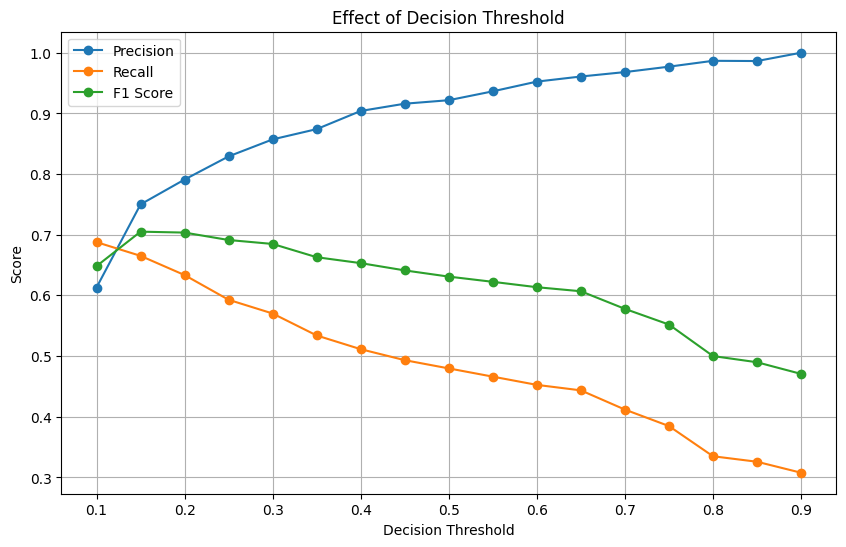

In [33]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Threshold"],
    results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["Threshold"],
    results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["Threshold"],
    results_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Effect of Decision Threshold")
plt.legend()
plt.grid()
plt.show()

In [34]:
best_threshold = results_df.loc[
    results_df["F1"].idxmax(),
    "Threshold"
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.15000000000000002


In [35]:
y_pred = (y_prob >= best_threshold).astype(int)

12. Classification report

In [36]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Fraud"]
    )
)

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      7557
       Fraud       0.75      0.67      0.71       221

    accuracy                           0.98      7778
   macro avg       0.87      0.83      0.85      7778
weighted avg       0.98      0.98      0.98      7778



13. Confusion Matrix

In [37]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[7508   49]
 [  74  147]]


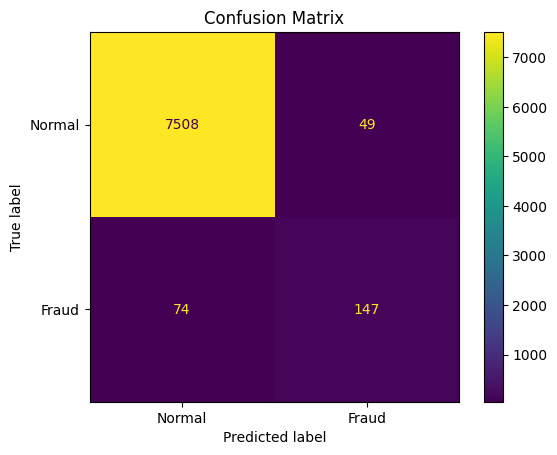

In [38]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

14. PR-AUC

In [39]:
pr_auc = average_precision_score(y_test, y_prob)

print("PR-AUC:", pr_auc)

PR-AUC: 0.7244579544099139


15. Feature Importance

In [40]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

In [41]:
print(feature_importance.head(20))

          Feature  Importance
236          V198    0.051722
4           card3    0.042393
275          V237    0.037414
194          V156    0.036644
17             C8    0.033835
322          V284    0.026388
355          V317    0.024541
332          V294    0.021966
95            V57    0.021536
354          V316    0.021229
413  card6_credit    0.019080
16             C7    0.018887
544    M4_Missing    0.017291
13             C4    0.016817
290          V252    0.015766
269          V231    0.014840
271          V233    0.012683
183          V145    0.012624
107           V69    0.011694
235          V197    0.011378


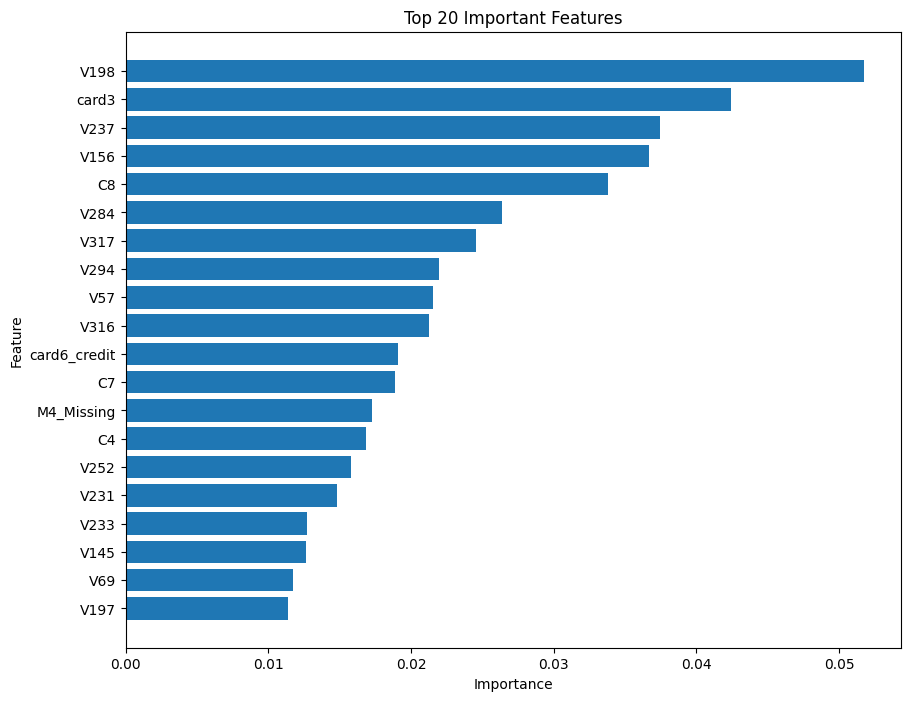

In [42]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Important Features")
plt.show()